# Agregación con cópulas, dependencia de cola y la asignación de Euler

**Pregunta:** Con las mismas cuatro marginales y la misma matriz de correlación, ¿cuánto más capital necesita Banco Andino
cuando sus riesgos se atan con una cópula t de Student en vez de una gaussiana, y qué riesgo carga la cola adicional?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** el notebook 01 de este tema (la suma simple y la regla de la raíz cuadrada)
- **Tiempo de lectura:** unos 50 minutos

## Objetivos

Al terminar este notebook puedes:

- decir qué es una cópula (teorema de Sklar), generar uniformes con la cópula gaussiana y con la t de Student y decir qué
  es la dependencia de cola, con la forma cerrada de los coeficientes de la t y de Clayton;
- convertir las cuatro marginales de Banco Andino en una simulación de las cuatro pérdidas y leer el VaR, la pérdida
  esperada en la cola y el capital económico de su suma;
- ver por qué la cópula t de Student pide más capital que la gaussiana con la misma correlación, y cuánto más con cada
  grado de libertad;
- repartir la pérdida esperada en la cola del total entre los cuatro riesgos con el principio de Euler, comprobar que las
  contribuciones suman exactamente, y comparar con la asignación en forma cerrada de la regla de la raíz cuadrada.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. Un notebook nunca instala nada por sí mismo. Los identificadores de las pruebas del motor se imprimen tal como los escribe el motor. Sus mensajes y notas están escritos en inglés: el árbol inglés los imprime como están, y este árbol imprime una traducción desde una tabla del notebook que falla si el motor cambia el texto.

La celda siguiente importa lo que usa el notebook e imprime las versiones de los paquetes, para que las compares con las fijadas.

In [1]:
# Importaciones, versiones y lector de los documentos versionados (tres carpetas bajo la raíz del repositorio)
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import stats
from riskvalidation.aggregation import copulas as cop
from riskvalidation.aggregation import simple
from riskvalidation.portfolio import euler
from riskvalidation.portfolio import portfolio as rv_port
from riskvalidation.validation import portfolio as port_tests

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))
DERIVED = Path("../../..").resolve() / "data" / "derived"


def read_json(relative):
    return json.loads((DERIVED / relative).read_text(encoding="utf-8"))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Este notebook lee el mismo caso del notebook 01, **C18** (Banco Andino).

- **Propietario y licencia:** los documentos los escribe el flujo sin conexión de este repositorio (`data-pipeline/pipeline/cases/c18/`) con el motor `riskvalidation` y se versionan en `data/derived/C18/`. Las trayectorias de escenario vienen de la Reserva Federal (dominio público), de la EBA y la ESRB (reproducción autorizada citando la fuente) y de la NGFS (solo derivado: únicamente las pocas variables que usa el caso). **Banco Andino es un banco sintético**: su cartera y su capital están calibrados a agregados públicos, y las trayectorias son trayectorias reales de Estados Unidos y de la zona euro trasladadas a su punto de partida, así que los satélites son una adaptación calibrada en EE. UU.
- **Estatus de verdad:** `synthetic-calibrated`. No hay respuesta publicada para el banco; las verificaciones de este notebook son recálculos de números versionados con el motor, no comparaciones con un resultado publicado.
- **Horneado con:** `riskvalidation` 0.8.1 (semilla 42), la versión que instala este notebook, así que se espera que un recálculo coincida hasta el redondeo.
- **Archivos leídos:** `data/derived/C18/baseline.json` (`outputs.aggregation`: las marginales, la matriz de correlación, el conjunto de grados de libertad, la banda versionada y la asignación de Euler versionada), `data/derived/C18/t-copula-baseline.json` (el mismo bloque con el estrés de la correlación mercado-crédito) y `data/derived/C18/models-banco-andino.json` (`fit.aggregation.quantile_grid`: la función de cuantiles de cada una de las cuatro marginales sobre una grilla de probabilidades nombrada, contrato `c18-models` 3.0.0).
- **Cómo se hicieron las filas versionadas.** El flujo de generación construye una muestra de un millón de pérdidas para cada marginal con el motor (crédito: la cópula agrupada de los segmentos de C07; mercado: una t de Student ajustada al VaR y al ES de C11; riesgo de tasa de interés: la simulación de Hull-White de C15; riesgo operacional: la agregación de Fourier del generador de C17), entrega las cuatro funciones de cuantiles a `dependence_band` y versiona el resultado. **Las cuatro muestras no están versionadas, pero sí la función de cuantiles de cada marginal**, sobre una grilla nombrada: las 1.961 probabilidades $\Phi(z)$ para $z$ de -4,9 a 4,9 en pasos de 0,005, densas en ambas colas. El paso 3 reconstruye las cuatro marginales desde las grillas por interpolación lineal en la probabilidad, la regla que la agregación aplica a la muestra ordenada, y el paso 4 corre sobre ellas la agregación del propio flujo de generación con su semilla, así que se espera recuperar las filas versionadas casi al dígito. Las filas versionadas se imprimen siempre al lado de las del notebook.

In [2]:
# El bloque de agregación base y las grillas de cuantiles versionadas de las cuatro marginales
agg = read_json("C18/baseline.json")["outputs"]["aggregation"]
grid = read_json("C18/models-banco-andino.json")["fit"]["aggregation"]["quantile_grid"]
marginals = agg["marginals"]
risks = [m["risk"] for m in marginals]
R = np.array(agg["correlation"]["matrix"])
NU_SET = agg["nu_set"]["values"]
committed = {(r["method"], r["nu"]): r for r in agg["band"]}
LABEL = {"credit": "crédito", "market": "mercado", "irrbb": "tasa de interés",
         "operational": "operacional"}
names = [LABEL[r] for r in risks]

## Método

### Paso 1: una cópula y su dependencia de cola

**Teorema de Sklar.** Toda distribución conjunta de pérdidas $L_1, \dots, L_d$ con funciones de distribución marginales $F_k$ se puede escribir $F(x_1, \dots, x_d) = C(F_1(x_1), \dots, F_d(x_d))$, donde la cópula $C$ lleva toda la dependencia y las $F_k$ llevan todo el comportamiento marginal. La agregación con cópula tiene entonces tres partes: elegir las marginales, elegir $C$ y simular $L_k = F_k^{-1}(U_k)$ con $U \sim C$ (dossier 05, G.1 ítem 3; McNeil, Frey y Embrechts 2015, cuyo número de capítulo es NO VERIFICADO en el dossier).

- **Cópula gaussiana** con matriz de correlación $R$: $U = \Phi(Z)$ con $Z \sim N(0, R)$ (Li 2000). No tiene dependencia de cola para $|\rho| < 1$: los extremos de dos riesgos se vuelven independientes lo bastante adentro de la cola.
- **Cópula t de Student** con $\nu$ grados de libertad: $U = t_\nu(X)$ con $X = \sqrt{\nu / \chi^2_\nu}\, Z$ (Frey y McNeil 2003; Demarta y McNeil 2005). Su **coeficiente de dependencia de cola** bivariado, el límite de $P(U_2 > q \mid U_1 > q)$ cuando $q \to 1$, es
$$\lambda = 2\, t_{\nu+1}\!\left(-\sqrt{\frac{(\nu+1)(1-\rho)}{1+\rho}}\right).$$
- **Cópula de Clayton** (bivariada): $C_\theta(u, v) = (u^{-\theta} + v^{-\theta} - 1)^{-1/\theta}$ con $\theta > 0$, y dependencia de cola inferior $\lambda_L = 2^{-1/\theta}$. El motor tiene las formas cerradas de Clayton pero no la muestrea (el docstring del módulo deja para después el muestreo de Clayton y las cópulas vine).

La celda siguiente dibuja el coeficiente de dependencia de cola de la cópula t contra la correlación para cada grado de
libertad del caso, marca la correlación propia del caso de 0,5, e imprime el coeficiente ahí junto a las formas cerradas de
Clayton.

t, rho = 0.5, nu =    4:  0.2532
t, rho = 0.5, nu =    8:  0.1173
t, rho = 0.5, nu =   30:  0.003


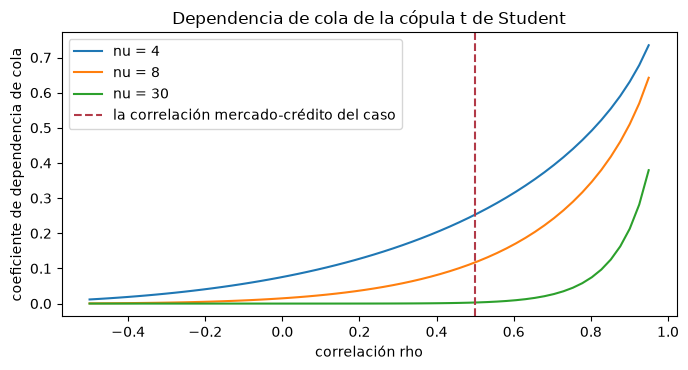

Clayton theta = 0.5: 0.25
Clayton theta = 1.0: 0.5
Clayton theta = 2.0: 0.7071


In [3]:
# La dependencia de cola de la t contra la correlación para cada nu del caso, y las formas cerradas de Clayton
rho_grid = np.linspace(-0.5, 0.95, 60)
fig, ax = plt.subplots(figsize=(7, 3.8))
for nu in NU_SET:
    ax.plot(rho_grid, [cop.t_tail_dependence(r, nu) for r in rho_grid], label=f"nu = {nu:g}")
    print(f"t, rho = 0.5, nu = {nu:4.0f}: ", round(cop.t_tail_dependence(0.5, nu), 4))
ax.axvline(0.5, color="#b23a48", linestyle="--", label="la correlación mercado-crédito del caso")
ax.set_xlabel("correlación rho")
ax.set_ylabel("coeficiente de dependencia de cola")
ax.set_title("Dependencia de cola de la cópula t de Student")
ax.legend()
fig.tight_layout()
plt.show()
for theta in (0.5, 1.0, 2.0):
    print(f"Clayton theta = {theta}:", round(cop.clayton_lower_tail_dependence(theta), 4))

Cada curva sube con la correlación y cae rápido cuando crecen los grados de libertad: con la correlación del caso, 0,5, el
coeficiente es 0,2532 con cuatro grados de libertad, 0,1173 con ocho y 0,0030 con treinta, y por eso el caso usa una cópula t
con treinta grados de libertad como sustituto de la gaussiana. Una cópula gaussiana sería una línea plana en cero. Los
números de Clayton impresos bajo la figura muestran la otra forma de obtener dependencia de cola, un solo parámetro que
carga solo la cola inferior; el motor tiene sus formas cerradas pero no la simula, así que aquí queda como fórmula.

### Paso 2: simular uniformes y medir la cola

`simulate_copula_uniforms(corr, family, nu, n, seed)` devuelve $n \times K$ uniformes con la cópula de la matriz `corr`. Ambas familias dan la misma correlación de rangos: la $\tau$ de Kendall de un par es $(2/\pi)\arcsin\rho$, 0,3333 para $\rho = 0,5$, así que un estadístico de rangos no distingue las cópulas. Lo que cambia es la esquina.

La celda siguiente genera un millón de pares de cada cópula con correlación 0,5 mediante `simulate_copula_uniforms`, cuenta
las excedencias conjuntas en tres niveles y dispersa cuatro mil pares de cada una, con la esquina de 0,99 marcada.

Gaussiana P(U2 > q dado U1 > q) con q = 0.9, 0.99, 0.999 [0.3222 0.1278 0.0552]
t (nu=4) P(U2 > q dado U1 > q) con q = 0.9, 0.99, 0.999 [0.3849 0.2816 0.2784]


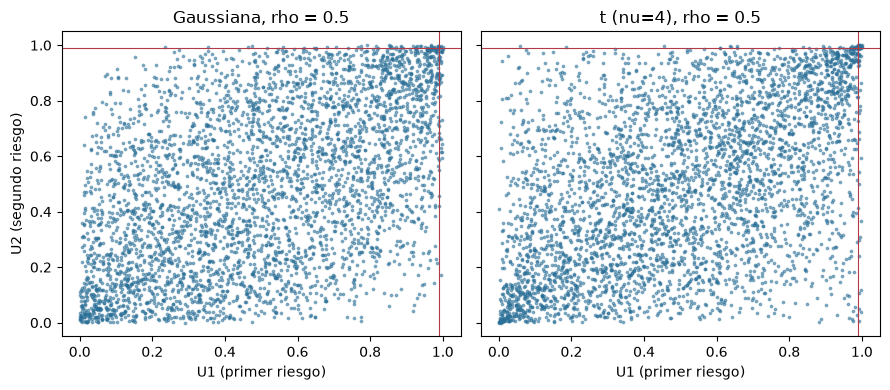

In [4]:
# Generar un millón de pares de la cópula gaussiana y de la t(4) con rho = 0,5, contar excedencias conjuntas y
# dispersar
pair = np.array([[1.0, 0.5], [0.5, 1.0]])
draws = {"Gaussiana": cop.simulate_copula_uniforms(pair, "gaussian", None, 1_000_000, 7),
         "t (nu=4)": cop.simulate_copula_uniforms(pair, "t", 4.0, 1_000_000, 7)}
fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharex=True, sharey=True)
for ax, (name, u) in zip(axes, draws.items()):
    ax.scatter(u[:4000, 0], u[:4000, 1], s=3, alpha=0.5, color="#2a6f97")
    ax.axvline(0.99, color="#b23a48", linewidth=0.8)
    ax.axhline(0.99, color="#b23a48", linewidth=0.8)
    ax.set_title(f"{name}, rho = 0.5")
    ax.set_xlabel("U1 (primer riesgo)")
    hits = [float((u[u[:, 0] > q, 1] > q).mean()) for q in (0.9, 0.99, 0.999)]
    print(name, "P(U2 > q dado U1 > q) con q = 0.9, 0.99, 0.999", np.round(hits, 4))
axes[0].set_ylabel("U2 (segundo riesgo)")
fig.tight_layout()
plt.show()

Las dos nubes tienen el mismo centro y la misma correlación de rangos, una tau de Kendall de 0,3333 para una correlación de
0,5, así que ningún estadístico de rangos las distingue. Lo que difiere es la esquina: la cópula t pone visiblemente más
puntos arriba a la derecha y abajo a la izquierda, que para pérdidas es donde ambos riesgos salen mal juntos. Los conteos
dicen lo mismo con números: dado que el primer riesgo supera su cuantil de 99,9 por ciento, el segundo también lo supera
con probabilidad 0,0552 bajo la cópula gaussiana y 0,2784 bajo la t con cuatro grados de libertad, frente a un límite de
0,2532. Con un millón de simulaciones solo unos mil pares llegan a esa esquina, así que la estimación es un retrato del
límite y no una medición de él.

### Paso 3: las marginales

La cópula necesita una función de cuantiles $F_k^{-1}$ para cada riesgo, y el caso las versiona. Para cada marginal el documento de modelos guarda su cuantil en las probabilidades $\Phi(z)$, $z = -4{,}9; -4{,}895; \dots; 4{,}9$ (1.961 puntos, en millones de CLP), desde cerca de $5 \times 10^{-7}$ hasta $1 - 5 \times 10^{-7}$, el alcance de la primera y la última de las $10^6$ simulaciones. Entre dos puntos la función de cuantiles es lineal en la probabilidad y queda fija en los extremos, que es la regla de `marginal_ppf_sample` del motor aplicada a una muestra ordenada. No se ajusta nada: la forma de cada marginal, la cola pesada del riesgo operacional incluida, es la del flujo de generación.

La celda siguiente reconstruye las cuatro funciones de cuantiles por interpolación lineal de las grillas versionadas, lee de
cada una una muestra de $10^6$ posiciones de Hazen y dibuja las cuatro funciones de cuantiles contra el puntaje normal
estándar $z$ del nivel de probabilidad. El VaR y el ES que leen los estimadores del motor de cada muestra se imprimen junto
a los versionados.

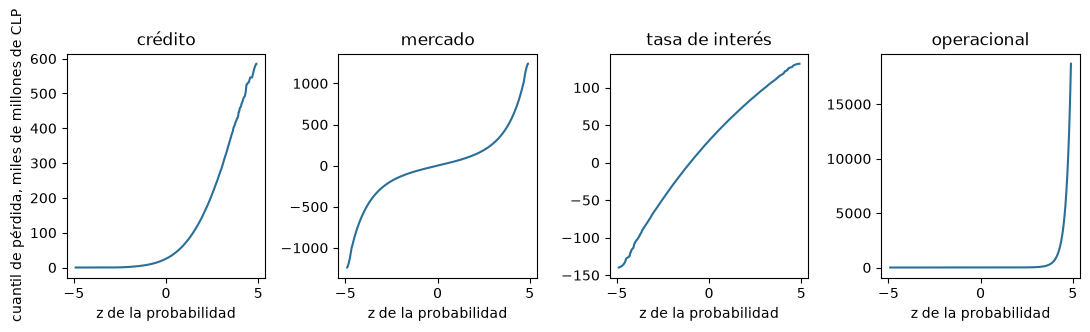

crédito          VaR    298239 (   298227)  ES    346964 (   346949)
mercado          VaR    283436 (   283435)  ES    355807 (   355803)
tasa de interés  VaR    100747 (   100746)  ES    106381 (   106382)
operacional      VaR     42357 (    42367)  ES    173668 (   171091)


In [5]:
# Reconstruir las cuatro marginales desde las grillas de cuantiles versionadas y leer su VaR y ES con el motor
LEVEL = 0.999
probs = np.array(grid["probabilities"])
positions = (np.arange(1, 1_000_001) - 0.5) / 1_000_000
ppfs, samples = [], {}
fig, axes = plt.subplots(1, 4, figsize=(11, 3.2))
for ax, m, q in zip(axes, marginals, grid["marginals"]):
    quantiles = np.array(q["quantiles"])
    ppfs.append(lambda u, x=quantiles: np.interp(np.asarray(u, dtype=float), probs, x))
    samples[m["risk"]] = np.interp(positions, probs, quantiles)
    ax.plot(stats.norm.ppf(probs), quantiles / 1e3, color="#2a6f97")
    ax.set_title(LABEL[m["risk"]])
    ax.set_xlabel("z de la probabilidad")
axes[0].set_ylabel("cuantil de pérdida, miles de millones de CLP")
fig.tight_layout()
plt.show()
for m in marginals:
    var_here = rv_port.var_from_sample(samples[m["risk"]], LEVEL)
    es_here = rv_port.es_from_sample(samples[m["risk"]], LEVEL)
    row = (LABEL[m["risk"]], var_here, m["var_clp_m"], es_here, m["es_clp_m"])
    print("%-16s VaR %9.0f (%9.0f)  ES %9.0f (%9.0f)" % row)

Cada panel es la pérdida que no se supera con cierta probabilidad, dibujada contra el puntaje normal de esa probabilidad,
de modo que una recta sería una marginal normal. El crédito se curva suavemente, el riesgo de mercado es simétrico en torno
a cero, el de tasa de interés es casi lineal y el operacional es plano casi todo el rango y se dispara en la última décima
del eje: la cola pesada. En este notebook no se ajusta nada, las formas son las propias del caso. El VaR impreso coincide
con el versionado entre paréntesis dentro de 0,03 por ciento, por ejemplo 298.239 contra 298.227 en crédito, y el ES del
riesgo operacional da 173.668 contra 171.091, un 1,5 por ciento más, porque la cifra versionada sale de la grilla de
severidad y esta de una muestra de la grilla interpolada.

### Paso 4: simular las cuatro pérdidas y agregar

`simulate_component_losses(ppfs, corr, family, nu, n_draws, seed, chunk_size)` genera los uniformes del paso 2 para los cuatro riesgos y pasa cada uno por su función de cuantiles, dando una matriz de $n \times 4$ pérdidas $L_k = F_k^{-1}(U_k)$. El total de un escenario es la suma de la fila. `copula_aggregate` hace lo mismo y devuelve el VaR, el ES y el capital económico $EC = \mathrm{VaR} - \sum_k \mathrm{EL}_k$ del total, con sus errores estándar de Monte Carlo (medias por lotes).

La celda siguiente simula una vez las cuatro pérdidas con la cópula gaussiana e imprime los primeros escenarios junto a sus
sumas por fila, luego ejecuta las cinco agregaciones del caso con `copula_aggregate` y dibuja su capital económico junto a
la banda versionada, con la suma simple y el total de la raíz cuadrada como líneas de referencia.

In [6]:
# Una simulación fila por fila, luego las agregaciones del caso con los ajustes del propio flujo de generación
SEED, CHUNK, N_DRAWS = 42, 100_000, 1_000_000
el_total = sum(m["el_clp_m"] for m in marginals)
joint = cop.simulate_component_losses(ppfs, R, "gaussian", None, N_DRAWS, SEED, CHUNK)
total = joint.sum(axis=1)
print("tres primeros escenarios, millones de CLP", np.round(joint[:3], 0).tolist())
print("sus sumas por fila", np.round(total[:3], 0).tolist())
keys = [("gaussian-copula", None)] + [("t-copula", nu) for nu in NU_SET]
here = {}
for key in keys:
    family = "gaussian" if key[1] is None else "t"
    here[key] = cop.copula_aggregate(ppfs, R, family, key[1], el_total, LEVEL, N_DRAWS, SEED, CHUNK)
    print(f"{key[0]:16s} nu={str(key[1]):5s} EC {here[key].ec:10,.0f}  se {here[key].var_se:7,.0f}")

tres primeros escenarios, millones de CLP [[34585.0, -40953.0, 41628.0, 1244.0], [1959.0, -141702.0, -6731.0, 376.0], [24746.0, -40887.0, 41590.0, 1070.0]]
sus sumas por fila [36504.0, -146098.0, 26518.0]
gaussian-copula  nu=None  EC    491,999  se   2,554
t-copula         nu=4.0   EC    552,369  se   3,430
t-copula         nu=8.0   EC    528,318  se   2,794
t-copula         nu=30.0  EC    499,133  se   3,281


Los cinco capitales ya están en `here`; la celda siguiente los dibuja junto a las filas de la banda versionada e imprime
cuánto sobre la fila gaussiana queda cada fila t.

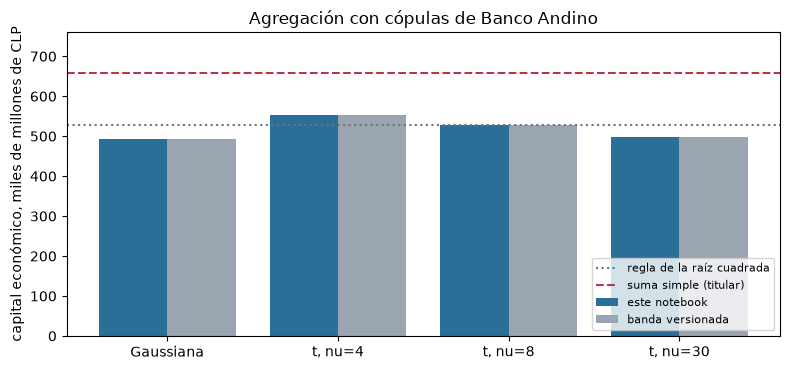

{'nu=4': 12.3, 'nu=8': 7.4, 'nu=30': 1.5}
sobre la fila gaussiana, porcentaje


In [7]:
# Los cinco capitales económicos junto a las filas versionadas de la banda, con los dos totales en forma cerrada
# como líneas
labels = ["Gaussiana" if k[1] is None else f"t, nu={k[1]:g}" for k in keys]
x = np.arange(len(keys))
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(x - 0.2, [here[k].ec / 1e3 for k in keys], width=0.4, label="este notebook", color="#2a6f97")
baked = [committed[k]["capital_clp_m"] / 1e3 for k in keys]
ax.bar(x + 0.2, baked, width=0.4, label="banda versionada", color="#9aa5b1")
ax.axhline(simple.variance_covariance(np.array([m["ec_clp_m"] for m in marginals]), R) / 1e3, color="#6c757d",
           linestyle=":", label="regla de la raíz cuadrada")
ax.axhline(agg["headline"]["capital_clp_m"] / 1e3, color="#b23a48", linestyle="--", label="suma simple (titular)")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(0, 760)
ax.set_ylabel("capital económico, miles de millones de CLP")
ax.set_title("Agregación con cópulas de Banco Andino")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
plt.show()
gaussian_ec = here[keys[0]].ec
print({f"nu={k[1]:g}": round((here[k].ec / gaussian_ec - 1) * 100, 1) for k in keys[1:]})
print("sobre la fila gaussiana, porcentaje")

El orden es el que predice la teoría: la cópula gaussiana abajo, luego la t con treinta grados de libertad, luego ocho, luego
cuatro. Con las mismas marginales y la misma matriz de correlación, cuanto más gruesa la dependencia de cola, más capital:
las filas t quedan 1,5; 7,4 y 12,3 por ciento sobre la fila gaussiana, y todas quedan bajo la suma simple. Reconstruidas
desde las grillas versionadas con la semilla del flujo, las cuatro filas caen sobre las versionadas con tres decimales
(491.999 contra 491.974 para la cópula gaussiana), diferencias mucho menores que el error estándar de Monte Carlo de 2.554
a 3.430 impreso en la celda anterior. La figura muestra que la elección de cópula pesa hasta 12 por ciento del capital; no
dice qué cópula es la correcta, que es la pregunta del notebook 07.

### Paso 5: la asignación de Euler de la pérdida esperada en la cola

Un total de $d$ riesgos se puede repartir en $d$ contribuciones que lo suman. Para una medida de riesgo $\rho$ positivamente homogénea de grado uno, la **contribución de Euler** del riesgo $k$ es la derivada de la medida del total cuando crece el tamaño del riesgo $k$, $\rho(L_k \mid L) = \frac{d}{dh}\rho(L + h L_k)\big|_{h=0}$, y las contribuciones suman $\rho(L)$ (Tasche 2007, Definición 2.2 y Observación 2.1). Para la pérdida esperada en la cola la contribución es una media condicional,

$$\mathrm{ES}_\alpha(L_k \mid L) = E\,[L_k \mid L \ge \mathrm{VaR}_\alpha(L)],$$

y `es_contributions` del motor la estima desde la muestra con los pesos de Acerbi y Tasche, de modo que las contribuciones suman el ES de la muestra exactamente. La contribución del VaR condiciona en un punto y es muy ruidosa en simulación, por eso el caso reparte el ES.

La celda siguiente reparte la pérdida esperada en la cola del agregado gaussiano del paso 4 con `es_contributions`, corre la
prueba de aditividad del motor y dibuja la parte de la cola de cada riesgo junto a su parte de la suma simple. El
**beneficio de Euler** de un riesgo es $1 - \mathrm{ES}(L_k \mid L)/\mathrm{ES}(L_k)$.

ES del total 709403  additivity gap|brecha de aditividad 0.0


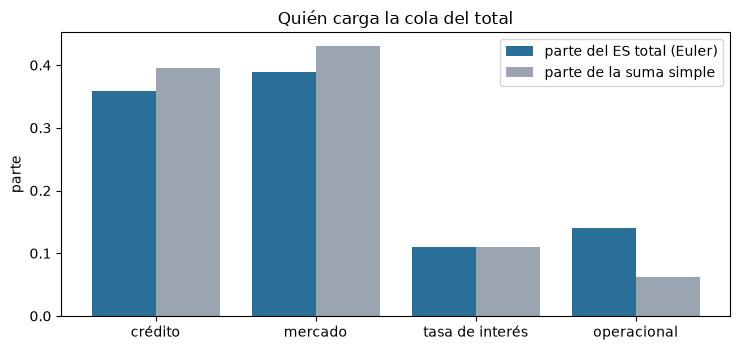

parte de la cola {'crédito': 0.359, 'mercado': 0.389, 'tasa de interés': 0.111, 'operacional': 0.141}
porcentaje, cola y suma simple [35.9 38.9 11.1 14.1] [39.6 43.1 11.1  6.3]
beneficio de Euler {'crédito': 0.264, 'mercado': 0.225, 'tasa de interés': 0.263, 'operacional': 0.458}


In [8]:
# Repartir el ES del agregado gaussiano, probar la aditividad y dibujar la parte de la cola de cada riesgo
es_total = rv_port.es_from_sample(total, LEVEL)
contributions = euler.es_contributions(joint, total, LEVEL)
additivity = port_tests.euler_additivity(contributions, es_total, 1e-6, model_id="notebook")
ec = np.array([m["ec_clp_m"] for m in marginals])
print("ES del total", round(es_total), " additivity gap|brecha de aditividad", additivity.metric)
tail_share = contributions / es_total
sum_share = ec / ec.sum()
benefit = [simple.euler_diversification_benefit(contributions[k], rv_port.es_from_sample(joint[:, k], LEVEL))
           for k in range(len(risks))]
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.bar(np.arange(4) - 0.2, tail_share, width=0.4, color="#2a6f97", label="parte del ES total (Euler)")
ax.bar(np.arange(4) + 0.2, sum_share, width=0.4, color="#9aa5b1", label="parte de la suma simple")
ax.set_xticks(np.arange(4))
ax.set_xticklabels(names)
ax.set_ylabel("parte")
ax.set_title("Quién carga la cola del total")
ax.legend()
fig.tight_layout()
plt.show()
print("parte de la cola", {k: round(float(v), 3) for k, v in zip(names, tail_share)})
print("porcentaje, cola y suma simple", np.round(tail_share * 100, 1), np.round(sum_share * 100, 1))
print("beneficio de Euler", {k: round(float(v), 3) for k, v in zip(names, benefit)})

La asignación suma el total exactamente, porque los pesos están construidos para eso, y lo que revela es dónde vive la cola.
El crédito carga 35,9 por ciento de la pérdida esperada en la cola total y el riesgo de mercado 38,9 por ciento, cerca de sus
partes de la suma simple, pero el riesgo operacional carga 14,1 por ciento de la cola frente a 6,3 por ciento de la suma
simple: su marginal tiene cola pesada (su pérdida esperada en la cola es cuatro veces su VaR), así que pesa más en los años
que duelen. Su beneficio de Euler de 0,458 es también el mayor, porque es grande solo en años en que los otros no lo son.
Una asignación vale lo que valen las colas sobre las que se calculó, y estas son las versionadas.

**La asignación en forma cerrada de la regla de la raíz cuadrada.** Para el total de varianza-covarianza no hay simulación:
con $\Sigma_{jk} = R_{jk}\,EC_j\,EC_k$ la medida de desviación estándar $\sqrt{\mathbf 1^{\top}\Sigma\,\mathbf 1}$ es
homogénea y sus contribuciones de Euler son $(\Sigma\mathbf 1)_k / \sqrt{\mathbf 1^{\top}\Sigma\,\mathbf 1}$ (Tasche 2007,
ecuación 3.4). `std_contributions` del motor las calcula, y la celda siguiente reparte el total de la raíz cuadrada del
notebook 01 e imprime el beneficio de Euler de cada riesgo.

In [9]:
# La asignación de Euler en forma cerrada del total de la raíz cuadrada y el beneficio de cada riesgo
sigma = R * np.outer(ec, ec)
std_parts = simple.std_contributions(sigma)
total_vc = simple.variance_covariance(ec, R)
print("total de la raíz cuadrada", round(total_vc, 1))
print("suma de contribuciones", round(float(std_parts.sum()), 1))
for risk, part, own in zip(names, std_parts, ec):
    print(f"{risk:16s} {part:10,.0f} {own:10,.0f} {simple.euler_diversification_benefit(part, own):.3f}")

total de la raíz cuadrada 528106.3
suma de contribuciones 528106.3
crédito             220,570    260,607 0.154
mercado             246,017    283,435 0.132
tasa de interés      48,688     72,824 0.331
operacional          12,831     41,179 0.688


## Resultados

Dos asignaciones de los mismos cuatro riesgos dan dos retratos distintos de quién se beneficia. Sobre la cola simulada de la
cópula gaussiana los beneficios son 0,264; 0,225; 0,263 y 0,458 para crédito, mercado, tasa de interés y operacional; con
la regla de la raíz cuadrada son 0,154; 0,132; 0,331 y 0,688, donde cuanto menor el riesgo, mayor su beneficio. La primera
asignación lee la cola, la segunda lee una covarianza, y quien elige una asignación elige una medida de riesgo.

**Respuesta:** una cópula t de Student con cuatro grados de libertad pide 552.369 millones de pesos con las marginales y la
correlación del caso, 12,3 por ciento más que los 491.999 millones de la cópula gaussiana, con 7,4 por ciento más con ocho
grados de libertad y 1,5 por ciento con treinta; la cola adicional es real porque el coeficiente de la t es 0,2532 con cuatro
grados de libertad y el gaussiano es cero. La cola la cargan sobre todo el riesgo de mercado (38,9 por ciento del ES de
709.403 millones) y el crédito (35,9 por ciento), y el riesgo operacional carga 14,1 por ciento frente a 6,3 por ciento de la
suma simple. La asignación de la raíz cuadrada suma 528.106 millones.

Lo que este notebook no muestra: las muestras de un millón de simulaciones detrás de las filas versionadas no están
versionadas, así que las marginales salen de una grilla de 1.961 puntos y las filas coinciden hasta 0,01 por ciento y no
hasta el último dígito; la cópula de Clayton aparece solo en forma cerrada porque el motor no la simula; y toda fila depende
de una matriz de correlación que es una convención.

## Resumen

- Una cópula separa la dependencia de las marginales (Sklar); agregar es: elegir las marginales, elegir la cópula, simular $L_k = F_k^{-1}(U_k)$ y leer el VaR, el ES y el EC de la suma de la fila.
- La cópula gaussiana y la t comparten la misma correlación de rangos pero no la esquina: la t tiene dependencia de cola $\lambda = 2\,t_{\nu+1}(\cdot)$, la gaussiana ninguna, y una simulación muestra la diferencia.
- El documento de modelos versionado guarda la función de cuantiles de cada marginal sobre una grilla nombrada, no el millón de pérdidas; este notebook reconstruyó las marginales desde ella y las filas versionadas volvieron con error menor que 0,01 por ciento, en el orden versionado.
- La asignación de Euler del ES suma el total exactamente y da a cada riesgo un beneficio; la regla de la raíz cuadrada tiene una asignación en forma cerrada que también suma.

**Qué probar a continuación.** Cambia la semilla del paso 4 y mira moverse el capital en torno a su error estándar; luego sigue con el notebook 03, que agrega las dos cotas que no dependen de ninguna cópula: el mejor y el peor VaR sobre toda dependencia.

## Referencias

- Rosenberg, J. V. y Schuermann, T. (2006), A general approach to integrated risk management with skewed, fat-tailed risks, Journal of Financial Economics 79(3). https://doi.org/10.1016/j.jfineco.2005.03.001
- Embrechts, P., Puccetti, G. y Rueschendorf, L. (2013), Model uncertainty and VaR aggregation, Journal of Banking and Finance 37(8). https://doi.org/10.1016/j.jbankfin.2013.03.014
- Tasche, D. (2007), Capital allocation to business units and sub-portfolios: the Euler principle (arXiv 0708.2542). https://arxiv.org/abs/0708.2542
- Embrechts, P., McNeil, A. y Straumann, D. (2002), Correlation and dependence in risk management: properties and pitfalls, en Dempster (ed.), Risk Management: Value at Risk and Beyond, Cambridge University Press. https://doi.org/10.1017/CBO9780511615337.008
- Li, D. X. (2000), la cópula gaussiana, y Frey, R. y McNeil, A. J. (2003) y Demarta, S. y McNeil, A. J. (2005), la cópula t, como los cita el docstring del módulo `riskvalidation.aggregation.copulas` del motor.
- Este repositorio: `docs/contracts/engine/aggregation-api.md`.